In [1]:
pip install requests beautifulsoup4

Note: you may need to restart the kernel to use updated packages.


In [3]:
# ==================================================
 SCRAPER UNE SEULE PAGE
# ==================================================

import requests
from bs4 import BeautifulSoup

url = "https://books.toscrape.com/catalogue/page-1.html"

# 1. Télécharger la page
reponse = requests.get(url)
print("Code de réponse :", reponse.status_code)

# 2. Lire le HTML avec BeautifulSoup
soup = BeautifulSoup(reponse.text, "html.parser")

# 3. Trouver tous les livres de la page
livres = soup.find_all("article", class_="product_pod")
print("Nombre de livres trouvés :", len(livres))

# 4. Extraire les infos du premier livre
premier = livres[0]
titre = premier.h3.a["title"]
prix = premier.find("p", class_="price_color").text
note = premier.find("p", class_="star-rating")["class"][1]

print("\nTitre :", titre)
print("Prix  :", prix)
print("Note  :", note)

Code de réponse : 200
Nombre de livres trouvés : 20

Titre : A Light in the Attic
Prix  : Â£51.77
Note  : Three


In [4]:
# ====================================================
# SCRAPER LES 50 PAGES
# ====================================================

import time
import pandas as pd

BASE_URL = "https://books.toscrape.com/catalogue/page-{}.html"

def scraper_page(numero_page):
    """Scrape une page du catalogue et retourne la liste des livres trouvés."""
    url = BASE_URL.format(numero_page)
    reponse = requests.get(url)
    reponse.encoding = "utf-8"          # corrige le problème du "Â£"

    if reponse.status_code != 200:      # page inaccessible : on signale l'échec
        return None

    soup = BeautifulSoup(reponse.text, "html.parser")
    livres = soup.find_all("article", class_="product_pod")

    resultats = []
    for livre in livres:
        resultats.append({
            "titre": livre.h3.a["title"],
            "prix": livre.find("p", class_="price_color").text,
            "note": livre.find("p", class_="star-rating")["class"][1],
            "disponibilite": livre.find("p", class_="instock availability").text.strip(),
            "page": numero_page
        })
    return resultats

# --- Boucle sur les 50 pages ---
tous_les_livres = []

for numero in range(1, 51):
    donnees = scraper_page(numero)

    if donnees is None:
        print(f" Page {numero} : échec, on passe à la suivante")
        continue

    tous_les_livres.extend(donnees)
    if numero % 10 == 0:
        print(f" {numero} pages scrapées — {len(tous_les_livres)} livres collectés")

    time.sleep(1)                       # pause d'1 seconde entre chaque page

# --- Conversion en tableau Pandas ---
df_livres = pd.DataFrame(tous_les_livres)
print(f"\n Résultat final : {df_livres.shape[0]} livres, {df_livres.shape[1]} colonnes")
df_livres.head()

 10 pages scrapées — 200 livres collectés
 20 pages scrapées — 400 livres collectés
 30 pages scrapées — 600 livres collectés
 40 pages scrapées — 800 livres collectés
 50 pages scrapées — 1000 livres collectés

 Résultat final : 1000 livres, 5 colonnes


,titre,prix,note,disponibilite,page
0,A Light in the Attic,£51.77,Three,In stock,1
1,Tipping the Velvet,£53.74,One,In stock,1
2,Soumission,£50.10,One,In stock,1
3,Sharp Objects,£47.82,Four,In stock,1
4,Sapiens: A Brief History of Humankind,£54.23,Five,In stock,1


In [5]:
# ==========================================================
#  NETTOYAGE DES DONNÉES SCRAPÉES
# ==========================================================

from datetime import datetime

# --- 1. Diagnostic : types et valeurs manquantes ---
print(" Types actuels :")
print(df_livres.dtypes)
print("\n Valeurs manquantes :", df_livres.isnull().sum().sum())
print(" Lignes en double :", df_livres.duplicated().sum())
print("\n Valeurs de disponibilité :")
print(df_livres["disponibilite"].value_counts())

# --- 2. Prix : texte -> nombre décimal ---
df_livres["prix"] = df_livres["prix"].str.replace("£", "", regex=False).astype(float)

# --- 3. Note : mot -> nombre de 1 à 5 ---
correspondance_notes = {"One": 1, "Two": 2, "Three": 3, "Four": 4, "Five": 5}
df_livres["note"] = df_livres["note"].map(correspondance_notes)

# --- 4. Disponibilité : texte -> vrai/faux ---
df_livres["en_stock"] = df_livres["disponibilite"] == "In stock"
df_livres = df_livres.drop(columns=["disponibilite"])

# --- 5. Date de collecte (utile pour suivre l'évolution dans le temps) ---
df_livres["date_collecte"] = datetime.now().strftime("%Y-%m-%d %H:%M:%S")

# --- 6. Vérification finale ---
print("\n Types après nettoyage :")
print(df_livres.dtypes)
print("\n Statistiques des prix et notes :")
print(df_livres[["prix", "note"]].describe().round(2))
df_livres.head()

 Types actuels :
titre            object
prix             object
note             object
disponibilite    object
page              int64
dtype: object

 Valeurs manquantes : 0
 Lignes en double : 0

 Valeurs de disponibilité :
disponibilite
In stock    1000
Name: count, dtype: int64

 Types après nettoyage :
titre             object
prix             float64
note               int64
page               int64
en_stock            bool
date_collecte     object
dtype: object

 Statistiques des prix et notes :
          prix     note
count  1000.00  1000.00
mean     35.07     2.92
std      14.45     1.43
min      10.00     1.00
25%      22.11     2.00
50%      35.98     3.00
75%      47.46     4.00
max      59.99     5.00


,titre,prix,note,page,en_stock,date_collecte
0,A Light in the Attic,51.77,3,1,True,2026-11-20 07:20:42
1,Tipping the Velvet,53.74,1,1,True,2026-11-20 07:20:42
2,Soumission,50.10,1,1,True,2026-11-20 07:20:42
3,Sharp Objects,47.82,4,1,True,2026-11-20 07:20:42
4,Sapiens: A Brief History of Humankind,54.23,5,1,True,2026-11-20 07:20:42


In [4]:
# ============================================================
# STOCKAGE DANS SQLITE
# ============================================================

import sqlite3

# 1. Connexion : le fichier livres.db est créé s'il n'existe pas
connexion = sqlite3.connect("livres.db")

# 2. Écriture du DataFrame dans une table "livres"
df_livres.to_sql("livres", connexion, if_exists="append", index=False)

# 3. Vérification
verif = pd.read_sql("""
    SELECT COUNT(*)                    AS nb_lignes,
           COUNT(DISTINCT date_collecte) AS nb_collectes
    FROM livres
""", connexion)
print(verif)

# 4. Aperçu des premières lignes
pd.read_sql("SELECT * FROM livres LIMIT 5", connexion)

   nb_lignes  nb_collectes
0       1000             1


,titre,prix,note,page,en_stock,date_collecte
0,A Light in the Attic,51.77,3,1,1,2026-11-19 18:30:55
1,Tipping the Velvet,53.74,1,1,1,2026-11-19 18:30:55
2,Soumission,50.10,1,1,1,2026-11-19 18:30:55
3,Sharp Objects,47.82,4,1,1,2026-11-19 18:30:55
4,Sapiens: A Brief History of Humankind,54.23,5,1,1,2026-11-19 18:30:55


 Prix par note :

   note  nb_livres  prix_moyen  prix_min  prix_max
0     1        452       34.56     10.40     59.64
1     2        392       34.81     10.02     59.95
2     3        406       34.69     10.16     59.99
3     4        358       36.09     10.01     59.45
4     5        392       35.37     10.00     59.92

 Livres par tranche de prix :

       tranche_prix  nb_livres  note_moyenne
0  1. Moins de 20 £        392          2.96
1   2. De 20 à 40 £        802          2.85
2   3. 40 £ et plus        806          2.98

 Top 5 des livres 5 étoiles les plus chers :

                                            titre   prix
0                  The Barefoot Contessa Cookbook  59.92
1                  The Barefoot Contessa Cookbook  59.92
2                           Life Without a Recipe  59.04
3                           Life Without a Recipe  59.04
4  Approval Junkie: Adventures in Caring Too Much  58.81


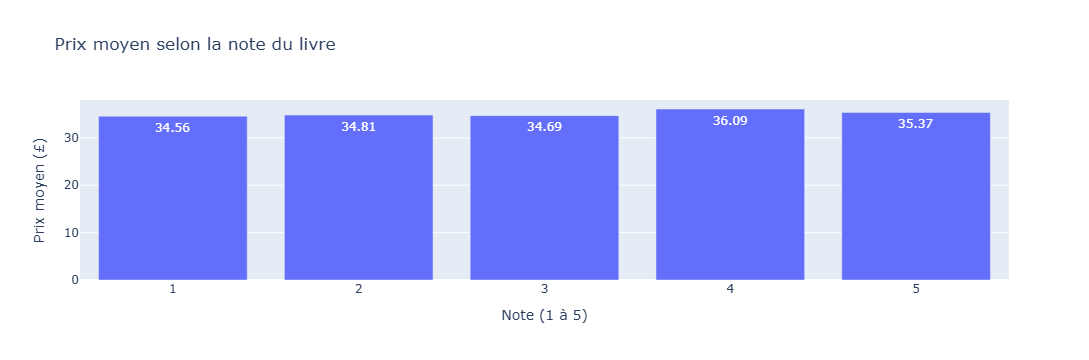

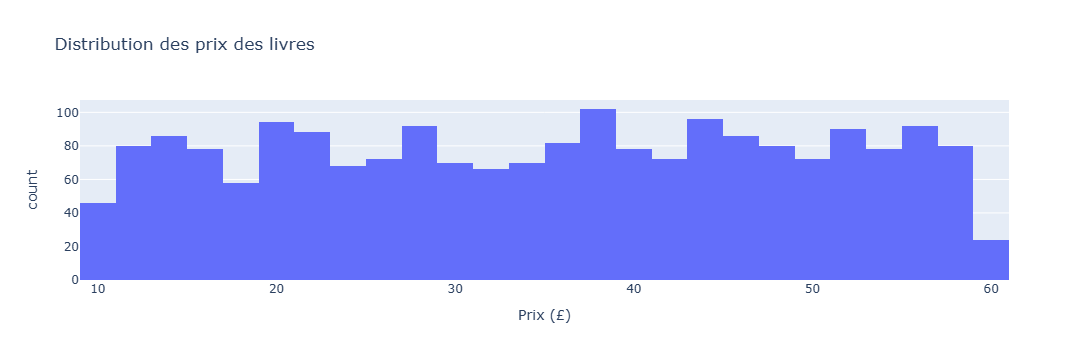

In [6]:
# ============================================================
# ANALYSE SQL + VISUALISATION (depuis SQLite)
# ============================================================

import plotly.express as px

# --- Requête 1 : prix et nombre de livres par note ---
q1 = pd.read_sql("""
    SELECT note,
           COUNT(*)              AS nb_livres,
           ROUND(AVG(prix), 2)   AS prix_moyen,
           MIN(prix)             AS prix_min,
           MAX(prix)             AS prix_max
    FROM livres
    GROUP BY note
    ORDER BY note
""", connexion)
print(" Prix par note :\n")
print(q1)

# --- Requête 2 : tranches de prix avec CASE WHEN ---
q2 = pd.read_sql("""
    SELECT CASE WHEN prix < 20 THEN '1. Moins de 20 £'
                WHEN prix < 40 THEN '2. De 20 à 40 £'
                ELSE '3. 40 £ et plus' END   AS tranche_prix,
           COUNT(*)                          AS nb_livres,
           ROUND(AVG(note), 2)               AS note_moyenne
    FROM livres
    GROUP BY tranche_prix
    ORDER BY tranche_prix
""", connexion)
print("\n Livres par tranche de prix :\n")
print(q2)

# --- Requête 3 : les 5 livres les plus chers parmi les 5 étoiles ---
q3 = pd.read_sql("""
    SELECT titre, prix
    FROM livres
    WHERE note = 5
    ORDER BY prix DESC
    LIMIT 5
""", connexion)
print("\n Top 5 des livres 5 étoiles les plus chers :\n")
print(q3)

# --- Graphique 1 : prix moyen par note ---
fig1 = px.bar(q1, x="note", y="prix_moyen",
              title="Prix moyen selon la note du livre",
              labels={"note": "Note (1 à 5)", "prix_moyen": "Prix moyen (£)"},
              text="prix_moyen")
fig1.show()

# --- Graphique 2 : distribution des prix ---
prix_data = pd.read_sql("SELECT prix FROM livres", connexion)
fig2 = px.histogram(prix_data, x="prix", nbins=25,
                    title="Distribution des prix des livres",
                    labels={"prix": "Prix (£)"})
fig2.show()

In [2]:
# ============================================================
#  VÉRIFIER L'HISTORIQUE DES COLLECTES
# ============================================================

import sqlite3
import pandas as pd

connexion = sqlite3.connect("livres.db")

pd.read_sql("""
    SELECT date_collecte,
           COUNT(*)            AS nb_livres,
           ROUND(AVG(prix), 2) AS prix_moyen
    FROM livres
    GROUP BY date_collecte
    ORDER BY date_collecte
""", connexion)

,date_collecte,nb_livres,prix_moyen
0,2026-11-20 06:19:37,1000,35.07
1,2026-11-20 06:32:15,1000,35.07
